# Study 18 — Beijing stress-test expansion

**Reviewer ask (detailed reviewer, Sec 3.8).** Report the Beijing contrasting-regime stress test more fully:
(a) all dropout levels, not just four; (b) AUPRC alongside AUROC given the different base rates; (c) calibration.

Reuses `study1_beijing_earlywarning.ipynb` (PRSA, 12 stations, TAU=75).

**Item (d), the networked variant (0.844 -> 0.857), is NOT in this notebook.** Its source data (the North China
Plain regional set) is no longer in the repo: `data/openaq_regional/regional_pm25.csv` now contains the Nordic
network only, so study2 can no longer be reproduced. Either restore the original regional CSV, or take the
reviewer's explicit alternative and remove the networked-variant claim.

cwd=`notebooks/`. Outputs -> `../outputs/study18_beijing_expand/`.


## Part A — Beijing single-station stress test (study1 pipeline)


In [1]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, math
from pathlib import Path
np.random.seed(20260608)
OUT=Path("../outputs/study18_beijing_expand"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
BASE="../data/beijing_air/PRSA_Data_20130301-20170228"
POLL=["PM2.5","PM10","SO2","NO2","CO","O3"]; MET=["TEMP","PRES","DEWP","WSPM"]; FEATS=POLL+MET
DIR={"PM2.5":1,"PM10":1,"SO2":1,"NO2":1,"CO":1,"O3":1,"TEMP":0,"PRES":0,"DEWP":1,"WSPM":-1}
TAU,STEP,H=75.0,6,4
stations={}
for f in sorted(glob.glob(BASE+"/PRSA_Data_*.csv")):
    d=pd.read_csv(f); d["dt"]=pd.to_datetime(d[["year","month","day","hour"]]); d=d.set_index("dt").sort_index()
    stations[d["station"].iloc[0]]=d[FEATS].resample(f"{STEP}h").mean()
allcat=pd.concat(stations.values()); norm={}
for c in FEATS:
    v=allcat[c].astype(float)
    if c in POLL: v=np.log1p(v.clip(lower=0))
    norm[c]=(v.mean(), v.std() if v.std()>1e-9 else 1.0)
def zcol(g,c):
    v=g[c].astype(float).to_numpy()
    if c in POLL: v=np.log1p(np.clip(v,0,None))
    mu,sd=norm[c]; return (v-mu)/sd
print(len(stations),"Beijing stations")


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


12 Beijing stations


In [2]:
K=5; LEV=np.linspace(0,1,K); SD=1.0+0.5*LEV; LOGC=0.5*np.log(2*np.pi)
def lgv(z): return -LOGC-np.log(SD)-0.5*((z-2.0*LEV)/SD)**2
W={c:(1.4 if c in POLL else 0.8) for c in FEATS}
def twin(zmat):
    prior=np.exp(-3*np.arange(K)); logb=np.log(prior/prior.sum()+1e-12); risk=np.empty(len(zmat))
    for t,row in enumerate(zmat):
        b=np.exp(logb-logb.max()); b/=b.sum(); el=(b*LEV).sum(); pdn=0.05 if el>0.4 else 0.15
        A=np.zeros((K,K))
        for k in range(K):
            up=0.25 if k<K-1 else 0; dn=pdn if k>0 else 0; A[k,k]=1-up-dn
            if k<K-1:A[k,k+1]=up
            if k>0:A[k,k-1]=dn
        logbp=np.log(b@A+1e-12); ll=np.zeros(K)
        for j,c in enumerate(FEATS):
            z=row[j]
            if np.isnan(z): continue
            ll+=W[c]*lgv(z*DIR[c])
        logt=logbp+ll; logb=logt-(logt.max()+np.log(np.exp(logt-logt.max()).sum())); risk[t]=float((np.exp(logb)*LEV).sum())
    return risk
def auc(s,yv):
    s=np.asarray(s,float);yv=np.asarray(yv,int);pos,neg=s[yv==1],s[yv==0]
    if len(pos)==0 or len(neg)==0:return float('nan')
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    _,inv,c=np.unique(s,return_inverse=True,return_counts=True);ss=np.zeros(len(c));np.add.at(ss,inv,r);r=(ss/c)[inv]
    return float((r[yv==1].sum()-len(pos)*(len(pos)+1)/2)/(len(pos)*len(neg)))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def ece(p,y,nb=10):
    p=np.asarray(p,float); y=np.asarray(y,float); ed=np.linspace(0,1,nb+1); e=0.0
    for i in range(nb):
        m=(p>=ed[i])&(p<ed[i+1] if i<nb-1 else p<=ed[i+1])
        if m.sum(): e+=m.mean()*abs(y[m].mean()-p[m].mean())
    return float(e)
def sig(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xb=np.hstack([np.ones((len(X),1)),(X-mu)/sd]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X): w,mu,sd=m; return sig(np.hstack([np.ones((len(X),1)),(np.asarray(X,float)-mu)/sd])@w)
ST={st:(np.column_stack([zcol(g,c) for c in FEATS]), g["PM2.5"].to_numpy(), g.index) for st,g in stations.items()}
RISK={st: twin(z) for st,(z,pm,ts) in ST.items()}
# onset table
rows=[]
for st,(z,pm,ts) in ST.items():
    risk=RISK[st]
    for t in range(2,len(pm)-H):
        if np.isnan(pm[t]) or pm[t]>=TAU: continue
        fut=pm[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        rows.append({"t":ts[t],"label":int(np.nanmax(fut)>=TAU),"twin_risk":risk[t],
                     **{f"z_{c}":(z[t,j] if not np.isnan(z[t,j]) else 0.0) for j,c in enumerate(FEATS)}})
S=pd.DataFrame(rows); S["mo"]=S.t.dt.month; tr=S[S.mo%2==0]; te=S[S.mo%2==1]
print("Beijing onset samples",len(S),"| prevalence %.3f"%S.label.mean())


Beijing onset samples 41715 | prevalence 0.404


### (a)+(b) Finer dropout grid with AUROC and AUPRC


In [3]:
def ffill(a):
    out=a.copy(); last=np.nan
    for i in range(len(out)):
        if np.isnan(out[i]): out[i]=last
        else: last=out[i]
    return out
def eval_dropout(frac,seed):
    rng=np.random.default_rng(seed); tw=[];lo=[];lab=[]
    for st,(z0,pm,ts) in ST.items():
        z=z0.copy()
        if frac>0: z[rng.random(z.shape)<frac]=np.nan
        risk=twin(z); pml=ffill(z[:,0])
        for t in range(2,len(pm)-H):
            if np.isnan(pm[t]) or pm[t]>=TAU: continue
            fut=pm[t+1:t+1+H]
            if np.all(np.isnan(fut)): continue
            lab.append(int(np.nanmax(fut)>=TAU)); tw.append(risk[t]); lo.append(pml[t] if not np.isnan(pml[t]) else 0.0)
    return auc(tw,lab),apr(tw,lab),auc(lo,lab),apr(lo,lab)
fracs=[0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.85,0.9]; rb=[]
for fr in fracs:
    seeds=range(1) if fr==0 else range(3)
    v=np.mean([eval_dropout(fr,30+s) for s in seeds],axis=0)
    rb.append({"dropout":fr,"twin_AUROC":v[0],"twin_AUPRC":v[1],"LOCF_AUROC":v[2],"LOCF_AUPRC":v[3],
               "AUROC_adv":v[0]-v[2],"AUPRC_adv":v[1]-v[3]})
robust=pd.DataFrame(rb); robust.to_csv(OUT/"s18_beijing_dropout_full.csv",index=False)
print(robust.round(3).to_string(index=False))


 dropout  twin_AUROC  twin_AUPRC  LOCF_AUROC  LOCF_AUPRC  AUROC_adv  AUPRC_adv
    0.00       0.723       0.609       0.745       0.645     -0.022     -0.036
    0.10       0.711       0.595       0.732       0.609     -0.021     -0.015
    0.20       0.700       0.581       0.719       0.584     -0.019     -0.003
    0.30       0.688       0.567       0.701       0.559     -0.014      0.009
    0.40       0.675       0.551       0.682       0.532     -0.007      0.019
    0.50       0.660       0.534       0.659       0.506      0.001      0.028
    0.60       0.644       0.516       0.630       0.479      0.014      0.037
    0.70       0.625       0.496       0.599       0.455      0.026      0.040
    0.80       0.599       0.469       0.565       0.435      0.034      0.035
    0.85       0.582       0.455       0.548       0.427      0.034      0.029
    0.90       0.561       0.439       0.533       0.422      0.029      0.017


### (c) Calibration: recalibrated twin vs multimodal logistic


In [4]:
zc=[f"z_{c}" for c in FEATS]; ytr,yte=tr.label.to_numpy(),te.label.to_numpy()
ftw=platt_fit(tr.twin_risk.values,ytr); p_twin=ftw(te.twin_risk.values)
p_log=predlog(fitlog(tr[zc].to_numpy(),ytr),te[zc].to_numpy())
cal=pd.DataFrame([
    ("twin (recalibrated)",auc(p_twin,yte),apr(p_twin,yte),brier(p_twin,yte),ece(p_twin,yte)),
    ("multimodal logistic",auc(p_log,yte),apr(p_log,yte),brier(p_log,yte),ece(p_log,yte)),
],columns=["model","AUROC","AUPRC","Brier","ECE"]).set_index("model")
print(cal.round(4).to_string()); cal.to_csv(OUT/"s18_beijing_calibration.csv")


                      AUROC   AUPRC   Brier     ECE
model                                              
twin (recalibrated)  0.7173  0.6220  0.2250  0.0475
multimodal logistic  0.7738  0.6846  0.1904  0.0189


## Figures


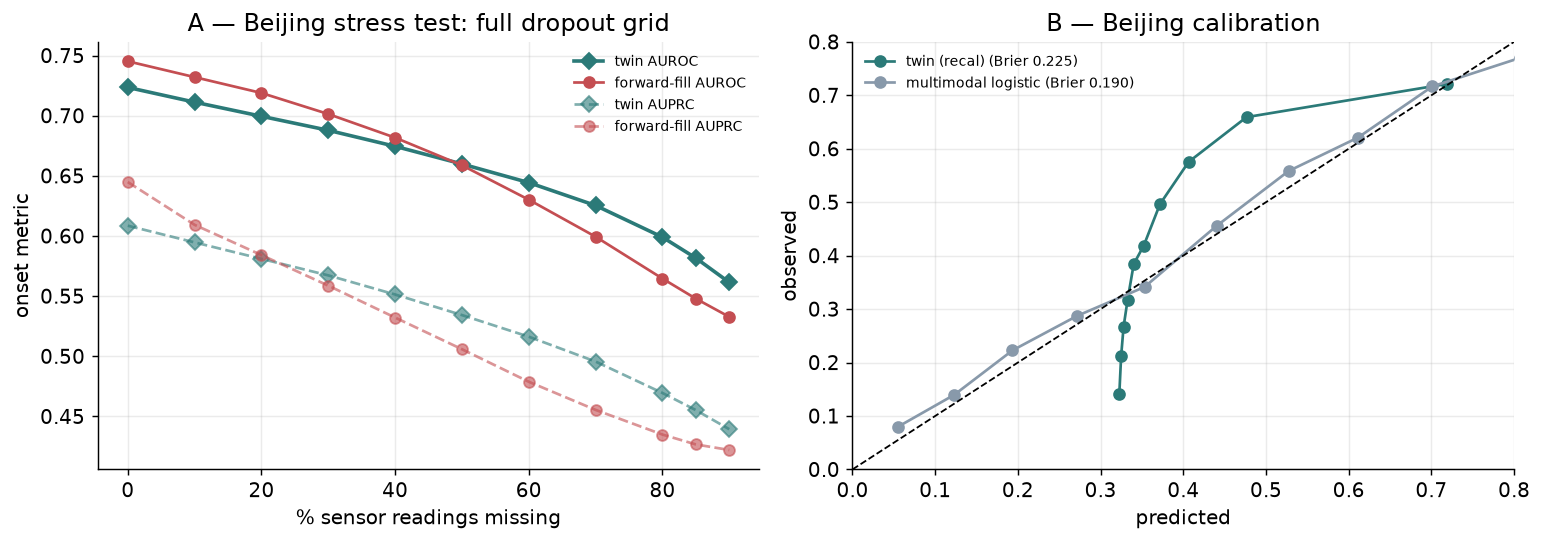

saved to ../outputs/study18_beijing_expand


In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
x=[f*100 for f in robust.dropout]
ax[0].plot(x,robust.twin_AUROC,"D-",color="#2b7a78",lw=2,label="twin AUROC")
ax[0].plot(x,robust.LOCF_AUROC,"o-",color="#C44E52",label="forward-fill AUROC")
ax[0].plot(x,robust.twin_AUPRC,"D--",color="#2b7a78",alpha=.6,label="twin AUPRC")
ax[0].plot(x,robust.LOCF_AUPRC,"o--",color="#C44E52",alpha=.6,label="forward-fill AUPRC")
ax[0].set_xlabel("% sensor readings missing"); ax[0].set_ylabel("onset metric")
ax[0].set_title("A — Beijing stress test: full dropout grid"); ax[0].legend(frameon=False,fontsize=8)
def rel(p,yy,nb=10):
    b=pd.qcut(p,nb,duplicates="drop"); grp=pd.DataFrame({"p":p,"y":yy}).groupby(b,observed=True); return grp.p.mean().values,grp.y.mean().values
mx=0.8
for p,lab,c in [(p_twin,"twin (recal)","#2b7a78"),(p_log,"multimodal logistic","#8899AA")]:
    xp,yp=rel(p,yte); ax[1].plot(xp,yp,"-o",label=f"{lab} (Brier {brier(p,yte):.3f})",color=c)
ax[1].plot([0,mx],[0,mx],"k--",lw=1); ax[1].set_xlim(0,mx); ax[1].set_ylim(0,mx)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed"); ax[1].set_title("B — Beijing calibration"); ax[1].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s18_fig1_beijing.png",bbox_inches="tight"); plt.show()
print("saved to",OUT)


## Reading this for the reply

- (a)+(b): report the full dropout grid with both AUROC and AUPRC (Table 6). Given the high Beijing base rate,
  AUPRC is informative and belongs beside AUROC.
- (c): report the Beijing calibration row (twin recalibrated vs multimodal logistic), consistent with the Nordic
  calibration treatment.
- (d) networked variant: blocked on missing data (see header). Decide with Edison whether to restore the North
  China Plain CSV and recompute the CI, or remove the claim as the reviewer permits.
